In [1]:
import pandas as pd

In [2]:
# For ignoring warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

## Load dataset

In [3]:
df = pd.read_csv('Iris.csv')
df.head(5)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## EDA

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [5]:
df.shape

(150, 6)

In [6]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [7]:
df['Species'].unique()

<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

In [8]:
import seaborn as sns

<Axes: >

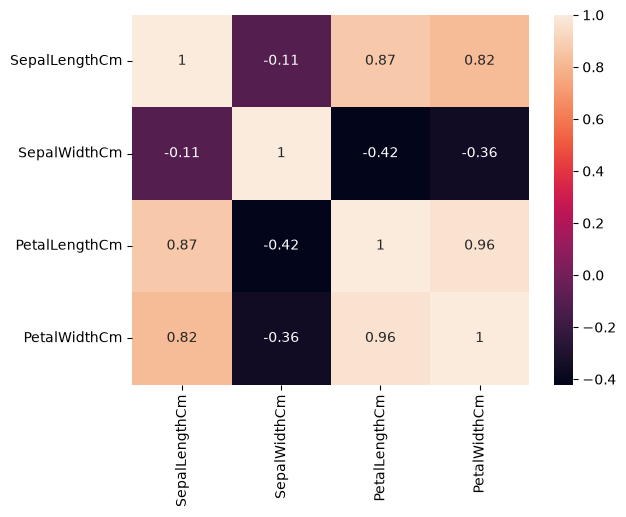

In [9]:
corr = df.drop(columns=['Id']).corr(numeric_only=True)
sns.heatmap(corr, annot=True)

This heatmap shows how strongly the four Iris features are related to each other. PetalLengthCm and PetalWidthCm are almost perfectly correlated (0.96), and both are also strongly linked to SepalLengthCm (0.87 and 0.82), meaning they tend to increase together. SepalWidthCm is the odd one out, with weak negative correlations (-0.11 to -0.42), so it behaves differently from the other features.

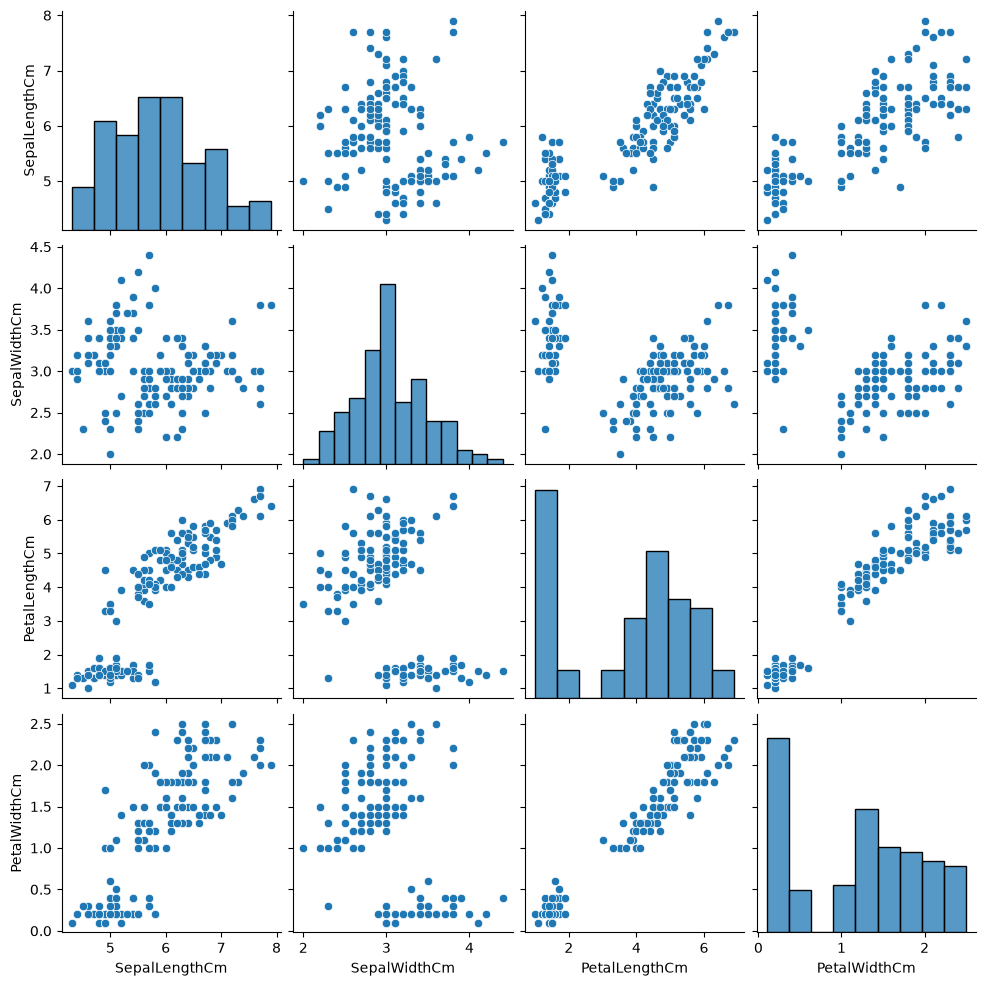

In [10]:
sns.pairplot(data=df.drop(columns=['Id']))

The scatter plots show that some data points naturally form groups based on their similarities, while others overlap. This suggests that clustering techniques, such as K-Means, can be used to identify and separate these groups based on their features.

## Data Preprocessing

In [11]:
df = df.drop(columns=['Id'])

In [12]:
df.head(3)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa


In [13]:
# Species label is not needed because the model that will be used is K Means (unsupervised)
x = df.drop(columns=['Species'])

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [15]:
# In Standard Scaler, mean will be = 0 (or close to 0)
x_scaled.mean(axis=0)

array([-4.73695157e-16, -6.63173220e-16,  3.31586610e-16, -2.84217094e-16])

In [16]:
# In Standard Scaler, standard deviation will be = 1 (or close to 1)
x_scaled.std(axis=0)

array([1., 1., 1., 1.])

## K-Means

In [17]:
from sklearn.cluster import KMeans

In [18]:
kmeans = KMeans(n_clusters=3, random_state=88)
df['Cluster'] = kmeans.fit_predict(x_scaled)

In [19]:
df.head(3)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1


In [20]:
df.groupby('Species')['Cluster'].value_counts()

Species          Cluster
Iris-setosa      1          50
Iris-versicolor  0          39
                 2          11
Iris-virginica   2          33
                 0          17
Name: count, dtype: int64

K-Means separated Iris-setosa perfectly (all 50 in one cluster). However, Iris-versicolor and Iris-virginica were partly mixed because their features overlap, with 11 versicolor and 17 virginica placed in the wrong cluster.

## Finding best number of cluster using Elbow Method and Silhouette Score

In [21]:
import matplotlib.pyplot as plt

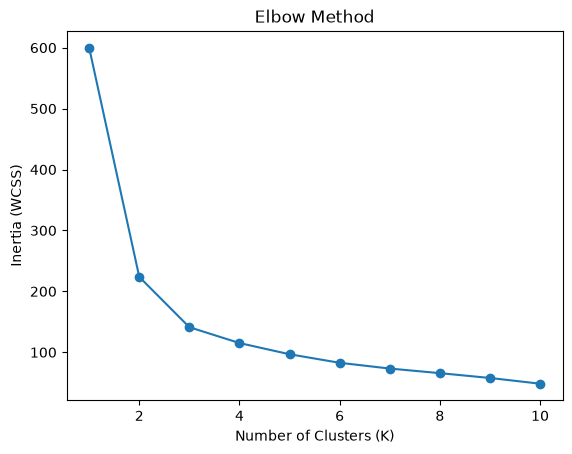

In [22]:
# Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=88)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.show()

The inertia drops sharply from K = 1 to K = 3, then the curve flattens out. This bend (the “elbow”) at K = 3 suggests that three clusters is a good choice, although K = 2 is also possible.

In [23]:
# Silhouette Score
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=88)
    labels = kmeans.fit_predict(x_scaled)
    scores.append(silhouette_score(x_scaled, labels))

scores

[0.580184463257396,
 0.46214947389312017,
 0.4055186142821239,
 0.34457631535828237,
 0.34946407538843355,
 0.33668387388570237,
 0.3128720752905609,
 0.3292419189479767,
 0.3541460652946237]

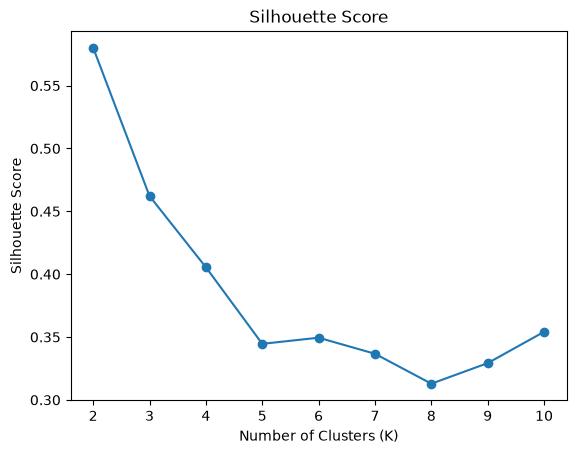

In [24]:
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.show()

The Silhouette Score is highest at K = 2 (about 0.58) and drops as K increases, so two clusters are separated most clearly. K = 3 has a lower but still acceptable score (about 0.46) and matches the real number of species.

In [25]:
# Results when number of cluster is 2
kmeans2 = KMeans(n_clusters=2, random_state=88)
df['Cluster2'] = kmeans2.fit_predict(x_scaled)
df.groupby('Species')['Cluster2'].value_counts()

Species          Cluster2
Iris-setosa      1           50
Iris-versicolor  0           50
Iris-virginica   0           50
Name: count, dtype: int64

With K=2, K-Means successfully separates all 50 Iris-setosa samples into one cluster. However, Iris-versicolor and Iris-virginica are grouped into the same cluster, showing that the model cannot distinguish between these two species when using only two clusters.

## Conclusion

Based on the Elbow Method and Silhouette Score, both K=2 and K=3 are reasonable choices. K=2 has the highest Silhouette Score (0.58) because Versicolor and Virginica are grouped together, while K=3 (0.46) matches the actual number of species. With K=3, K-Means perfectly separates Setosa, but 28 out of 100 Versicolor and Virginica samples are assigned to the wrong clusters because their features overlap.